# 1. Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
from sklearn.datasets import fetch_openml
from torchvision.datasets import EMNIST



# 2. Загрузка датасета

In [2]:
from torchvision.datasets import EMNIST

train_dataset = EMNIST(root="./data", split="digits", train=True, download=True)
test_dataset = EMNIST(root="./data", split="digits", train=False, download=True)

# Берём сразу 5000 обучающих и 10000 тестовых изображений с сохранением долей классов.
train_indices, _ = train_test_split(
    np.arange(len(train_dataset.targets)),
    train_size=5000,
    random_state=42,
    stratify=train_dataset.targets.numpy()
)
test_indices, _ = train_test_split(
    np.arange(len(test_dataset.targets)),
    train_size=10000,
    random_state=42,
    stratify=test_dataset.targets.numpy()
)

X_train_emnist = train_dataset.data.numpy()[train_indices]
y_train_emnist = train_dataset.targets.numpy()[train_indices]
X_test_emnist = test_dataset.data.numpy()[test_indices]
y_test_emnist = test_dataset.targets.numpy()[test_indices]

# Корректируем ориентацию EMNIST и приводим изображения к 784 признакам.
X_train_emnist = X_train_emnist.transpose(0, 2, 1).reshape(-1, 784)
X_test_emnist = X_test_emnist.transpose(0, 2, 1).reshape(-1, 784)

X = np.concatenate([X_train_emnist, X_test_emnist], axis=0)
y = np.concatenate([y_train_emnist, y_test_emnist], axis=0).astype(int)

print("Размер датасета:", X.shape)
print("Количество классов:", len(np.unique(y)))


Размер датасета: (15000, 784)
Количество классов: 10


# 3. Визуализация изображений

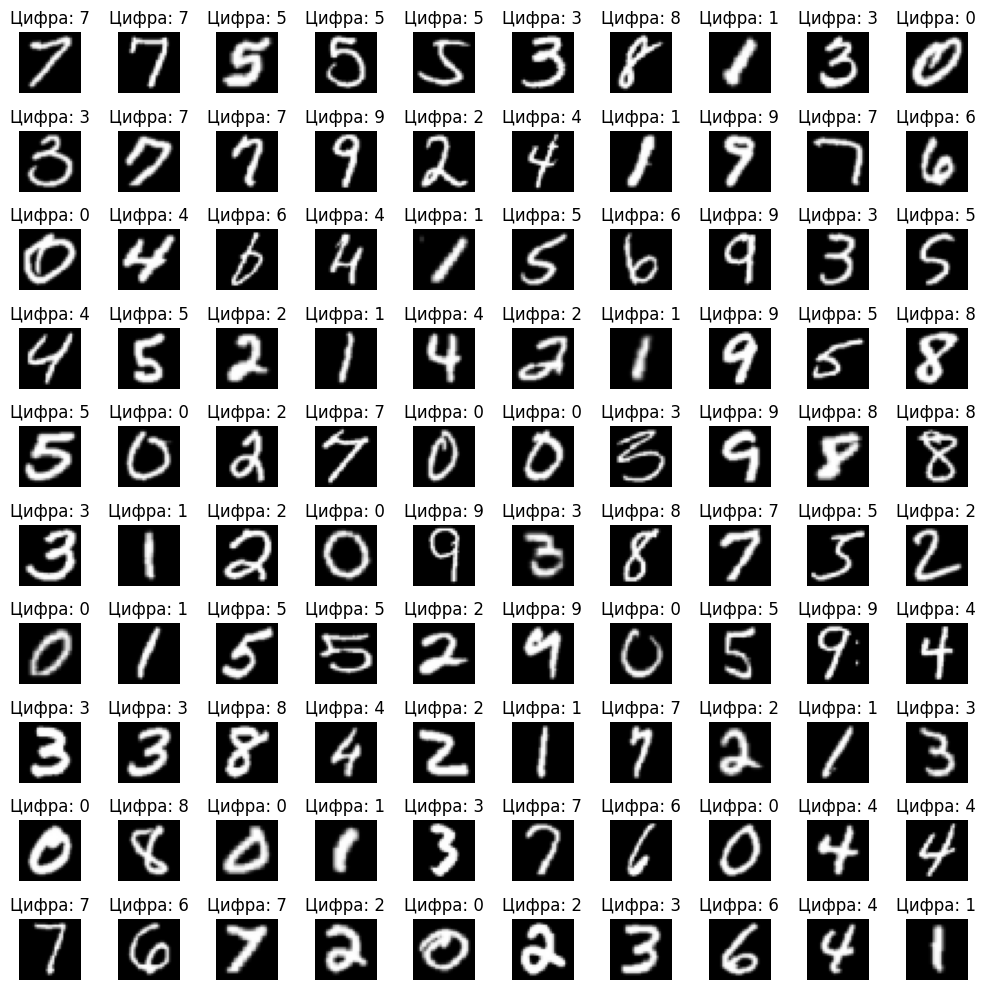

In [3]:
fig, axes = plt.subplots(10, 10, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Цифра: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 4. Разделение данных

In [4]:
from sklearn.model_selection import train_test_split

X_train = X[:5000]
y_train = y[:5000]

X_test = X[5000:]
y_test = y[5000:]

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Обучающая выборка: (5000, 784)
Тестовая выборка: (10000, 784)


# 5. Нормализация

In [5]:
X_train_scaled = X_train.astype(np.float32) / 255.0
X_test_scaled = X_test.astype(np.float32) / 255.0

# 6. Эксперимент: влияние количества размеченных данных и порога SSL

Сравниваем **Logistic Regression и SVM (RBF)**. В каждой группе используются одни и те же известные метки для всех моделей. Доли размеченных данных: **1%, 2.5%, 5%, 10%**; пороги Self-Training: **0.7, 0.8, 0.9**.

Обучаем **Supervised** на известной части выборки и **SSL** на всей обучающей выборке, где неизвестные метки отмечены `-1`. Тестовая выборка не участвует в обучении. Используем **macro**-усреднение метрик для 10 классов. Группы вложенные: метки из 1% входят в 2.5%, затем в 5% и 10%.

**Важно:** SVM с `probability=True` и многократный Self-Training вычислительно затратны; выполнение полного эксперимента может потребовать значительного времени.

In [6]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display
import time

RANDOM_STATE = 42
LABELED_FRACTIONS = [0.01, 0.025, 0.05, 0.10]
CONFIDENCE_THRESHOLDS = [0.7, 0.8, 0.9]
MAX_SSL_ITER = 10   # Для более долгого самообучения можно увеличить до 20

# Все модели имеют predict_proba — это необходимо для SelfTrainingClassifier.
MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=RANDOM_STATE),
}


## 6.1. Создаём группы с известными метками

В каждой группе ровно 1%, 2.5%, 5% или 10% из 5000 изображений размечено. По возможности сохраняем пропорции классов; индекс каждого более маленького набора входит в следующий. Все остальные изображения остаются доступными Self-Training без меток.

In [7]:
def make_label_groups(labels, fractions, seed=42):
    labels = np.asarray(labels)
    classes, counts = np.unique(labels, return_counts=True)
    rng = np.random.default_rng(seed)
    shuffled = {cls: rng.permutation(np.where(labels == cls)[0]) for cls in classes}
    groups = {}

    for fraction in sorted(fractions):
        target = round(len(labels) * fraction)
        # Сначала резервируем по одному примеру на класс.
        sizes = np.ones(len(classes), dtype=int)
        remaining = target - sizes.sum()
        if remaining < 0:
            raise ValueError("Слишком мало меток для количества классов")
        # Распределяем остаток по пропорциям классов методом наибольших остатков.
        weights = counts / counts.sum()
        allocation = remaining * weights
        sizes += np.floor(allocation).astype(int)
        for j in np.argsort(-(allocation - np.floor(allocation)))[:target - sizes.sum()]:
            sizes[j] += 1
        idx = np.concatenate([shuffled[cls][:n] for cls, n in zip(classes, sizes)])
        mask = np.zeros(len(labels), dtype=bool)
        mask[idx] = True
        groups[fraction] = mask
    return groups

label_groups = make_label_groups(y_train, LABELED_FRACTIONS, RANDOM_STATE)
for fraction, mask in label_groups.items():
    print(f"{fraction * 100:4g}%: размеченных {mask.sum():4d}, неразмеченных {(~mask).sum():4d}")


   1%: размеченных   50, неразмеченных 4950
 2.5%: размеченных  125, неразмеченных 4875
   5%: размеченных  250, неразмеченных 4750
  10%: размеченных  500, неразмеченных 4500


## 6.2. Запускаем Supervised и SSL для каждой комбинации

Для каждой доли меток и каждого алгоритма обучаем отдельную Supervised-модель, затем три модели SSL с разной уверенностью. Сохраняем также число псевдометок и прирост F1-score относительно Supervised при той же доле меток и том же алгоритме.

In [8]:
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

results = []
trained_models = {}  # При необходимости здесь доступны обученные модели.

for fraction, labeled_mask in label_groups.items():
    y_partial = np.full(y_train.shape, -1, dtype=int)
    y_partial[labeled_mask] = y_train[labeled_mask]
    n_labeled = int(labeled_mask.sum())
    n_unlabeled = int((~labeled_mask).sum())

    for model_name, estimator in MODELS.items():
        t0 = time.perf_counter()
        supervised = clone(estimator)
        supervised.fit(X_train_scaled[labeled_mask], y_train[labeled_mask])
        pred_supervised = supervised.predict(X_test_scaled)
        base_metrics = calculate_metrics(y_test, pred_supervised)
        results.append({
            "Доля меток, %": fraction * 100,
            "Модель": model_name,
            "Обучение": "Supervised",
            "Порог": np.nan,
            "Размечено": n_labeled,
            "Псевдометок": 0,
            "Осталось без меток": n_unlabeled,
            **base_metrics,
            "Прирост F1, п.п.": 0.0,
            "Время, с": time.perf_counter() - t0,
        })
        trained_models[(fraction, model_name, "Supervised")] = supervised

        for threshold in CONFIDENCE_THRESHOLDS:
            t0 = time.perf_counter()
            ssl = SelfTrainingClassifier(
                estimator=clone(estimator),
                threshold=threshold,
                max_iter=MAX_SSL_ITER,
            )
            ssl.fit(X_train_scaled, y_partial.copy())
            pred_ssl = ssl.predict(X_test_scaled)
            ssl_metrics = calculate_metrics(y_test, pred_ssl)
            n_pseudo = int(np.sum((y_partial == -1) & (ssl.transduction_ != -1)))
            results.append({
                "Доля меток, %": fraction * 100,
                "Модель": model_name,
                "Обучение": "Self-Training",
                "Порог": threshold,
                "Размечено": n_labeled,
                "Псевдометок": n_pseudo,
                "Осталось без меток": n_unlabeled - n_pseudo,
                **ssl_metrics,
                "Прирост F1, п.п.": 100 * (ssl_metrics["F1-score"] - base_metrics["F1-score"]),
                "Время, с": time.perf_counter() - t0,
            })
            trained_models[(fraction, model_name, threshold)] = ssl
            print(f"Метки: {fraction*100:4g}% | {model_name:20s} | порог {threshold:.1f} | "
                  f"F1={ssl_metrics['F1-score']:.4f} | +{n_pseudo} псевдометок", flush=True)

results_df = pd.DataFrame(results)
assert len(results_df) == 4 * 2 * (1 + 3)


Метки:    1% | Logistic Regression  | порог 0.7 | F1=0.7151 | +4723 псевдометок
Метки:    1% | Logistic Regression  | порог 0.8 | F1=0.7088 | +4470 псевдометок
Метки:    1% | Logistic Regression  | порог 0.9 | F1=0.6790 | +3957 псевдометок
Метки:    1% | SVM (RBF)            | порог 0.7 | F1=0.4516 | +3953 псевдометок
Метки:    1% | SVM (RBF)            | порог 0.8 | F1=0.6898 | +6 псевдометок
Метки:    1% | SVM (RBF)            | порог 0.9 | F1=0.6895 | +0 псевдометок
Метки:  2.5% | Logistic Regression  | порог 0.7 | F1=0.7943 | +4668 псевдометок
Метки:  2.5% | Logistic Regression  | порог 0.8 | F1=0.7995 | +4403 псевдометок
Метки:  2.5% | Logistic Regression  | порог 0.9 | F1=0.8062 | +3940 псевдометок
Метки:  2.5% | SVM (RBF)            | порог 0.7 | F1=0.8980 | +4602 псевдометок
Метки:  2.5% | SVM (RBF)            | порог 0.8 | F1=0.9003 | +4329 псевдометок
Метки:  2.5% | SVM (RBF)            | порог 0.9 | F1=0.7880 | +748 псевдометок
Метки:    5% | Logistic Regression  | порог 0.7

# 7. Итоговые таблицы

Полная таблица содержит все 32 эксперимента. Строки Supervised не имеют порога: он к ним неприменим.

In [9]:
display(results_df.round(4))


,"Доля меток, %",Модель,Обучение,Порог,Размечено,Псевдометок,Осталось без меток,Accuracy,Precision,Recall,F1-score,"Прирост F1, п.п.","Время, с"
0,1.0,Logistic Regression,Supervised,NaN,50,0,4950,0.6566,0.6825,0.6566,0.6536,0.0000,0.0833
1,1.0,Logistic Regression,Self-Training,0.7,50,4723,227,0.7164,0.7501,0.7164,0.7151,6.1439,2.7553
2,1.0,Logistic Regression,Self-Training,0.8,50,4470,480,0.7131,0.7534,0.7131,0.7088,5.5197,2.2078
3,1.0,Logistic Regression,Self-Training,0.9,50,3957,993,0.6971,0.7506,0.6971,0.6790,2.5391,1.3764
4,1.0,SVM (RBF),Supervised,NaN,50,0,4950,0.6923,0.7081,0.6923,0.6895,0.0000,0.1459
5,1.0,SVM (RBF),Self-Training,0.7,50,3953,997,0.5121,0.7531,0.5121,0.4516,-23.7879,23.6559
6,1.0,SVM (RBF),Self-Training,0.8,50,6,4944,0.6924,0.7083,0.6924,0.6898,0.0267,0.3313
7,1.0,SVM (RBF),Self-Training,0.9,50,0,4950,0.6923,0.7081,0.6923,0.6895,0.0000,0.2241
8,2.5,Logistic Regression,Supervised,NaN,125,0,4875,0.7494,0.7570,0.7494,0.7475,0.0000,0.0695
9,2.5,Logistic Regression,Self-Training,0.7,125,4668,207,0.7950,0.8067,0.7950,0.7943,4.6809,2.9315


## 7.1. Сравнение F1-score в компактной таблице

Каждая строка — комбинация доли размеченных данных и алгоритма. Можно сразу увидеть результаты обучения без SSL и при трёх порогах.

In [10]:
comparison_f1 = results_df.copy()
comparison_f1["Режим"] = comparison_f1.apply(
    lambda row: "Supervised" if row["Обучение"] == "Supervised"
    else f"SSL {row['Порог']:.1f}", axis=1
)
f1_table = comparison_f1.pivot(index=["Доля меток, %", "Модель"], columns="Режим", values="F1-score")
f1_table = f1_table[["Supervised", "SSL 0.7", "SSL 0.8", "SSL 0.9"]]
display(f1_table.round(4))


Режим                              Supervised  SSL 0.7  SSL 0.8  SSL 0.9
Доля меток, % Модель                                                    
1.0           Logistic Regression      0.6536   0.7151   0.7088   0.6790
              SVM (RBF)                0.6895   0.4516   0.6898   0.6895
2.5           Logistic Regression      0.7475   0.7943   0.7995   0.8062
              SVM (RBF)                0.7956   0.8980   0.9003   0.7880
5.0           Logistic Regression      0.8142   0.8434   0.8572   0.8615
              SVM (RBF)                0.8616   0.9261   0.9264   0.9126
10.0          Logistic Regression      0.8578   0.8806   0.8862   0.8874
              SVM (RBF)                0.9161   0.9466   0.9490   0.9429

## 7.2. Сколько псевдометок добавляет каждый порог

In [11]:
pseudo_table = results_df[results_df["Обучение"] == "Self-Training"].pivot(
    index=["Доля меток, %", "Модель"], columns="Порог", values="Псевдометок"
)
display(pseudo_table)


Порог                               0.7   0.8   0.9
Доля меток, % Модель                               
1.0           Logistic Regression  4723  4470  3957
              SVM (RBF)            3953     6     0
2.5           Logistic Regression  4668  4403  3940
              SVM (RBF)            4602  4329   748
5.0           Logistic Regression  4551  4299  3894
              SVM (RBF)            4477  4314  3433
10.0          Logistic Regression  4311  4113  3714
              SVM (RBF)            4274  4057  3582

## 7.3. Лучшая комбинация для каждой доли меток и алгоритма

Здесь выбираем лучшую SSL-конфигурацию по **F1-score** на тестовой выборке **только для анализа**, а не для окончательного подбора гиперпараметров. Для строгого выбора порога следует использовать отдельную валидационную выборку, а тест оставить для единственной финальной оценки.

In [12]:
ssl_rows = results_df[results_df["Обучение"] == "Self-Training"]
best_rows = ssl_rows.loc[ssl_rows.groupby(["Доля меток, %", "Модель"])["F1-score"].idxmax()]
display(best_rows[["Доля меток, %", "Модель", "Порог", "Accuracy", "Precision", "Recall", "F1-score", "Прирост F1, п.п.", "Псевдометок"]].sort_values(["Доля меток, %", "Модель"]).round(4))


,"Доля меток, %",Модель,Порог,Accuracy,Precision,Recall,F1-score,"Прирост F1, п.п.",Псевдометок
1,1.0,Logistic Regression,0.7,0.7164,0.7501,0.7164,0.7151,6.1439,4723
6,1.0,SVM (RBF),0.8,0.6924,0.7083,0.6924,0.6898,0.0267,6
11,2.5,Logistic Regression,0.9,0.8064,0.8201,0.8064,0.8062,5.8696,3940
14,2.5,SVM (RBF),0.8,0.8999,0.9087,0.8999,0.9003,10.4684,4329
19,5.0,Logistic Regression,0.9,0.8623,0.8641,0.8623,0.8615,4.7292,3894
22,5.0,SVM (RBF),0.8,0.9264,0.9281,0.9264,0.9264,6.4806,4314
27,10.0,Logistic Regression,0.9,0.8879,0.8882,0.8879,0.8874,2.9632,3714
30,10.0,SVM (RBF),0.8,0.9491,0.9492,0.9491,0.9490,3.2885,4057


# 8. Визуальное сравнение

Графики показывают изменение F1-score в зависимости от доли размеченных данных. Линии отражают режимы Supervised, SSL 0.7, SSL 0.8 и SSL 0.9.

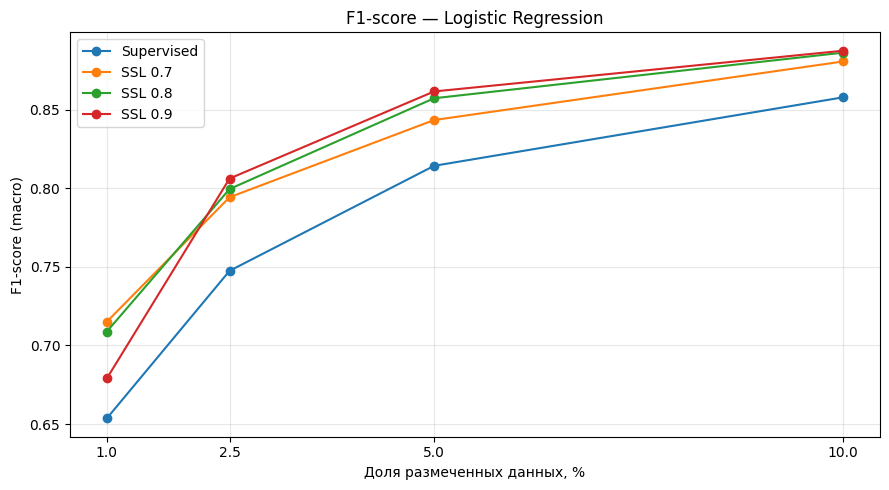

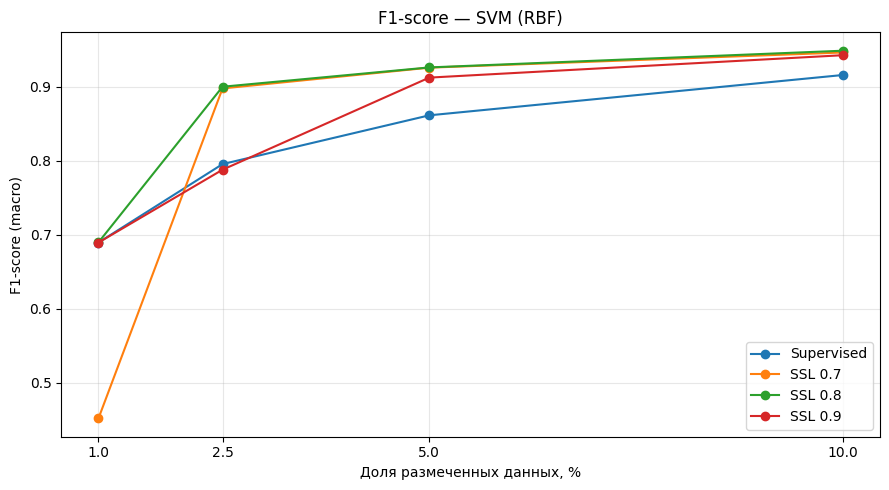

In [13]:
for model_name in MODELS:
    data = comparison_f1[comparison_f1["Модель"] == model_name]
    plt.figure(figsize=(9, 5))
    for mode in ["Supervised", "SSL 0.7", "SSL 0.8", "SSL 0.9"]:
        subset = data[data["Режим"] == mode].sort_values("Доля меток, %")
        plt.plot(subset["Доля меток, %"], subset["F1-score"], marker="o", label=mode)
    plt.title(f"F1-score — {model_name}")
    plt.xlabel("Доля размеченных данных, %")
    plt.ylabel("F1-score (macro)")
    plt.xticks([1, 2.5, 5, 10])
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


# 9. Сохранение результатов

При необходимости можно открыть CSV в Excel или использовать показатели для таблиц и диаграмм в курсовой работе.

In [15]:
results_df.to_csv("ssl_experiment_results.csv", index=False, encoding="utf-8-sig")
f1_table.to_csv("ssl_f1_comparison.csv", encoding="utf-8-sig")
print("Сохранены файлы ssl_experiment_results.csv и ssl_f1_comparison.csv")


Сохранены файлы ssl_experiment_results.csv и ssl_f1_comparison.csv


# 10. Интерфейс

In [16]:
from pathlib import Path
import joblib

output_dir = Path("ssl_streamlit") / "models"
output_dir.mkdir(parents=True, exist_ok=True)
name_map = {"Logistic Regression": "lr", "SVM (RBF)": "svm"}
for (fraction, model_name, mode), trained_model in trained_models.items():
    fraction_text = f"{fraction * 100:g}"
    prefix = f"{name_map[model_name]}_labeled_{fraction_text}"
    suffix = "sl" if mode == "Supervised" else f"ssl_{mode:.1f}"
    joblib.dump(trained_model, output_dir / f"{prefix}_{suffix}.joblib")
print("Модели сохранены в:", output_dir.resolve())


Модели сохранены в: /Users/timofeyvyalov/Downloads/num/ssl_streamlit/models
